## Importamos Librerias

In [197]:
!pip install -q spacy
!python -m spacy download es_core_news_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 68.5 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [198]:
!pip install nltk

In [199]:
import pandas as pd
pd.set_option('display.max_columns', None)
import nltk
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.tokenize import TweetTokenizer
from nltk.stem.snowball import SnowballStemmer
import textwrap
from collections import Counter
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import string
import re
import spacy


## Carga de datos

In [240]:
!wget -O datosMIT.csv 'https://www.dropbox.com/scl/fi/wsu8vit9fzhefs0e955sw/LIFT-Digitization-and-Performance-Index-Argentina-Fall-2025_October-29-2025_08.44.csv?rlkey=leozcj0vv8mlen24ny6lsy3j0&e=1&st=e57y7wql&dl=0'

--2026-09-20 21:52:10--  https://www.dropbox.com/scl/fi/wsu8vit9fzhefs0e955sw/LIFT-Digitization-and-Performance-Index-Argentina-Fall-2025_October-29-2025_08.44.csv?rlkey=leozcj0vv8mlen24ny6lsy3j0&e=1&st=e57y7wql&dl=0
Resolving www.dropbox.com (www.dropbox.com)... 162.125.5.18, 2620:100:601d:18::a27d:512
Connecting to www.dropbox.com (www.dropbox.com)|162.125.5.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://uc095c862048d827b77c0b7021d7.dl.dropboxusercontent.com/cd/0/inline/DIjV4lV-5uCI1_n66_aGzpKcXw3PhmpfPulgrGYo1CxPOFiU9R-IyA06NGMXWEjiC5vUTsYWX0Liyp5LwfBr5bwjbavTQtKTki7o6AOLsZeMX3w6mHoS2N9P5pJa_XlFdHJ0NflsyurvTL1_Q1DYPMuV/file# [following]
--2026-09-20 21:52:11--  https://uc095c862048d827b77c0b7021d7.dl.dropboxusercontent.com/cd/0/inline/DIjV4lV-5uCI1_n66_aGzpKcXw3PhmpfPulgrGYo1CxPOFiU9R-IyA06NGMXWEjiC5vUTsYWX0Liyp5LwfBr5bwjbavTQtKTki7o6AOLsZeMX3w6mHoS2N9P5pJa_XlFdHJ0NflsyurvTL1_Q1DYPMuV/file
Resolving uc095c862048d827b77c0b7021d7.dl.dropboxus

In [241]:
df = pd.read_csv('/content/datosMIT.csv', header=1)
df = df.drop(0).reset_index(drop=True)
cols = ['¿Tus ventas actuales están mejor, peor o igual en comparación con las de hace un mes?',
        '¿Por qué piensas que las ventas incrementaron/disminuyeron/permanecieron igual? (opcional)']
df = df[cols].copy()

In [242]:
df.shape

(923, 2)

In [243]:
# Sacamos nulos del campo de texto y renombramos a la columna
df = (df.dropna(subset=["¿Por qué piensas que las ventas incrementaron/disminuyeron/permanecieron igual? (opcional)"]).reset_index(drop=True))
df = df.rename(columns={'¿Por qué piensas que las ventas incrementaron/disminuyeron/permanecieron igual? (opcional)':'Motivo variacion ventas'})
df = df.rename(columns={'¿Tus ventas actuales están mejor, peor o igual en comparación con las de hace un mes?':'Ventas'})

Quedaron 703 filas

In [244]:
df

,Ventas,Motivo variacion ventas
0,Peor,Grandes empresarios aumentan los costos
1,Igual,Proximos meses: estacionalidad de las fiestas
2,Peor,Caída de ingesos de la poblacion
3,Igual,No contesta
4,Igual,Clima
...,...,...
698,Mejor,Porque las personas del barrio van conociendo ...
699,Igual,Contexto pais
700,Igual,De un mes a otro no influyo
701,Peor,jj


## Exploracion I

Distribucion de clases: bastante balanceada, la categoria 'Mejora' que es la mas importante es la minoritaria

In [245]:
for col in df.columns:
  print('Columna:', col)
  print(df[col].value_counts(normalize=False))
  print('Cantidad de valores ', df[col].nunique())

Columna: Ventas
Ventas
Peor     283
Igual    234
Mejor    186
Name: count, dtype: int64
Cantidad de valores  3
Columna: Motivo variacion ventas
Motivo variacion ventas
Estabilidad                                                     6
Estacionalidad                                                  6
Situación del país                                              5
Temporada                                                       4
-                                                               4
                                                               ..
No hay flujo de gente, no entran. Cree que no tiene dinero.     1
constancia de clientela                                         1
clientela constante                                             1
—                                                               1
El mes anterior fue muy malo                                    1
Name: count, Length: 637, dtype: int64
Cantidad de valores  637


In [246]:
df['Ventas'].value_counts(normalize=True)

,proportion
Ventas,
Peor,0.402560
Igual,0.332859
Mejor,0.264580


2. ¿Cómo es la longitud de los textos? ¿Hay documentos anormalmente largos o cortos?
Para responder esto necesitamos una manera de contar palabras / tokens / unidades de texto. Es decir, necesitamos tokenizar.

--> Cantidad de palabras

In [247]:
# A veces alcanza con contar espacios:
num_words = df['Motivo variacion ventas'].str.count(" ") + 1
num_words.describe()

,Motivo variacion ventas
count,703.000000
mean,6.812233
std,5.996344
min,1.000000
25%,3.000000
50%,5.000000
75%,9.000000
max,61.000000


In [248]:
num_chars = df['Motivo variacion ventas'].str.len()
num_chars.describe()

,Motivo variacion ventas
count,703.000000
mean,38.170697
std,33.470221
min,1.000000
25%,18.000000
50%,29.000000
75%,50.000000
max,326.000000


Caracteres raros

In [249]:
mask = df['Motivo variacion ventas'].str.contains("&amp;")
print(df['Motivo variacion ventas'][mask].shape)

(0,)


In [250]:
mask = df['Motivo variacion ventas'].str.contains("\\\\n") # tienen "\n" literales
print(df['Motivo variacion ventas'][mask].shape)

(0,)


In [251]:
text_col = ('Motivo variacion ventas')

# Para el EDA conservamos el texto tal como fue escrito.
tokenizer = TweetTokenizer(
    strip_handles=False,
    reduce_len=False
)

# Ejemplo de tokenización
example = df[text_col].iloc[0]
tokens_example = tokenizer.tokenize(example)

print("Texto original:")
print(example)

print("\nTokens:")
print(tokens_example)


Texto original:
Grandes empresarios aumentan los costos

Tokens:
['Grandes', 'empresarios', 'aumentan', 'los', 'costos']


In [252]:

# Cantidad de tokens de cada respuesta
df["num_tokens"] = df[text_col].apply(
    lambda texto: len(tokenizer.tokenize(texto))
)

print(df["num_tokens"].describe())

# Tres respuestas más cortas y tres más largas
short_texts = (
    df.sort_values("num_tokens", ascending=True)
      .head(3)[[text_col, "num_tokens"]]
)

long_texts = (
    df.sort_values("num_tokens", ascending=False)
      .head(3)[[text_col, "num_tokens"]]
)

print("\n# Respuestas más cortas:")
for _, row in short_texts.iterrows():
    print(
        f"- {row['num_tokens']} tokens:",
        textwrap.fill(row[text_col], width=120)
    )

print("\n# Respuestas más largas:")
for _, row in long_texts.iterrows():
    print(
        f"- {row['num_tokens']} tokens:",
        textwrap.fill(row[text_col], width=120)
    )

count    703.000000
mean       6.991465
std        6.631526
min        1.000000
25%        3.000000
50%        5.000000
75%        9.000000
max       69.000000
Name: num_tokens, dtype: float64

# Respuestas más cortas:
- 1 tokens: jj
- 1 tokens: Clima
- 1 tokens: Temporada

# Respuestas más largas:
- 69 tokens: Por los impuestos de la ciudad de Tandil. Con el corte de obras públicas por parte del estado Nacional, cree que se dió
el alza de impuestos a nivel local. No hay consenso para reclamar. Pone como ejemplo beneficios por parte del Municipio
por ser buen contribuyente. La gente no llega a fin de mes, “fin de mes se adelantó”.
- 48 tokens: Hubieron días buenos durante el mes que compensaron los días buenos, las elecciones impactaron a principio de mes pero
se compensa mediante promociones. La gente aunque aumente el precio compra igual lo que necesita, eso hace que las
ventas dentro de todo se mantengan.
- 46 tokens: Porque ya tenemos bastantes años de experiencia, conseguimos clie

Duplicados: hay 66, pero tienen sentido, son palabras repetidas

In [253]:
print(df.iloc[:,1].duplicated().sum())

66


In [254]:
mask = df.iloc[:,1].duplicated(keep=False)
df.iloc[:,1][mask]

,Motivo variacion ventas
4,Clima
23,Temporada
30,Estabilidad
59,La gente no tiene plata
61,No sabe
...,...
641,La gente no tiene plata
648,Estacionalidad
666,Por la situación del país
673,Por el gobierno


Hacemos un modelo rapido para ver las frases que son raros respecto de su etiqueta

In [255]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression

vectorizer = CountVectorizer(max_features=150)
clf = LogisticRegression(max_iter=1000)
class2int = {label: i for i, label in enumerate(df.iloc[:,0].unique())}
int2class = {i: label for label, i in class2int.items()}

X_train = vectorizer.fit_transform(df.iloc[:,1])
y_train = df.iloc[:,0].map(class2int)

clf.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [256]:
# Ejemplos con mayor pérdida (medida como -log(probabilidad_clase_correcta)):
import numpy as np

y_pred_proba = clf.predict_proba(X_train)
loss = -np.log(y_pred_proba[range(len(y_train)), y_train])
y_pred = clf.predict(X_train)

df["pred"] = [int2class[i] for i in y_pred]
df["loss"] = loss

df.sort_values("loss", ascending=False).head(8)

,Ventas,Motivo variacion ventas,num_tokens,pred,loss
182,Igual,Situación económica del país,4,Peor,2.984419
200,Mejor,"Hay un colegio en frente, no les afecta mucho ...",13,Igual,2.798227
254,Peor,La zona en la que se encuentran y el clima,10,Mejor,2.787457
142,Peor,la temporada(estacionalidad),5,Mejor,2.434316
383,Peor,Por el clima. Generalmente vendemos más en inv...,15,Mejor,2.415923
390,Igual,Por la situación del país. Estacionalidad,7,Peor,2.409270
497,Mejor,Por la economía,3,Peor,2.332419
615,Mejor,La gente no piensa en otra cosa que en comer,10,Igual,2.203182


Tokenizamos y exploramos la cantidad de tokens y los mas repetidos

In [257]:
# Empecemos usando el tokenizador de tweets de nltk.
# Para cada documento queremos un vector del tamaño del vocabulario con la
# cantidad de veces que aparece cada palabra.
from nltk.tokenize import TweetTokenizer

tokenizer = TweetTokenizer(strip_handles=False, reduce_len=True)
vectorizer = CountVectorizer(tokenizer=tokenizer.tokenize)

X_train = vectorizer.fit_transform(df.iloc[:,1])
df_vocab_train = pd.DataFrame(X_train.toarray(), columns=vectorizer.get_feature_names_out())

print(df_vocab_train.shape)
df_vocab_train.head()

(703, 942)


/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


,"""",%,(,),",",-,.,/,1000,2,3,50,:,;,a,abrieron,abrió,aca,accesibles,aceptamos,aceptan,acerca,achica,acomodo,acortan,acostumbramos,actividad,actual,actualmente,adelante,adelantó,ademas,además,administra,administración,adopción,adquisición,adquisitivo,adquisivo,afecta,afuera,agosto,agregaron,ahora,ahorrando,ahí,aires,ajuste,al,ala,alcance,alcanza,algo,algunos,alimentos,almacen,almacén,almuerzo,alta,altos,alza,ambiente,animales,ante,anterior,antes,apertura,aplica,aprovechan,aproximación,apuntan,arg,armado,armo,arranco,articulos,asalariado,asentados,asentaron,atencion,atención,aumenta,aumentan,aumentar,aumentaria,aumentaron,aumente,aumento,aumentos,aumentó,aun,aunque,austero,ayuda,ayudan,año,años,aún,baja,bajan,bajando,bajaron,bajas,bajo,bajos,bajó,balance,bancarias,baratos,barrio,bastante,bastantes,bebida,bebidas,beneficios,bien,billeteras,bolsillo,buen,buena,bueno,buenos,busca,buscan,buscando,buscar,básica,básicos,cada,cafe,cafeterias,café,calidad,calle,calmó,calor,cambia,cambiaron,cambio,cambios,cambió,canales,canasta,cantidad,cantidades,capacitarme,capital,carbonatadas,carne,carnicería,caros,casanova,casi,catering,caudal,caída,cedió,celebraciones,cerca,cercanos,cercanía,cerrado,cerrar,chicos,chino,cierta,circulación,ciudad,cliente,clientela,clientes,clima,climatico,climáticas,cobrarle,colectividad,colegio,colegios,combos,come,comen,comer,comercio,comercios,comida,comidas,comienzo,como,comparación,compartir,compensa,compensaron,competencia,competitivos,complicado,comportamiento,compra,comprador,compran,comprando,comprar,compras,con,concesión,condiciones,conducta,conjunto,conocen,conocerlo,conocido,conociendo,conocimiento,conomiento,conseguimos,consenso,consideran,constancia,constante,construccion,consume,consumen,consumible,consumidor,consumidoras,consumidores,consumiendo,consumir,consumo,contesta,contexto,contribuyente,convenios,corrupción,cortar,corte,cosa,cosas,costo,costos,coyuntural,crecer,creciendo,crecimiento,cree,creo,crisis,cuando,cuenta,cuestiones,cuestión,cuida,cuidado,cuidarse,cumplen,da,de,debido,decadencia,decir,decisiones,dejan,dejaron,del,demanda,dentro,depende,dependiendo,desarrollada,descontento,descuentos,desde,despidos,despues,después,detalles,determinada,dia,dias,dieta,dieteticas,diferencia,diferenciados,difícil,dijo,dilatando,dinamica,dinero,disminución,disminuyen,disminuyeron,disminuyó,dispone,disponibilidad,disponible,distintas,diversificacion,dió,dni,dolar,domingo,dueño,dulces,durante,día,días,dólar,e,econlmica,economia,economica,economicas,economico,economía,económica,económica-tuvieron,económicas,económico,económicos,efectivo,egresados,ejemplo,el,elecciones,elección,electoral,elegir,eligen,ellos,empeoró,empezando,empezo,empezó,empieza,empiezan,empleados,empresarios,empresas,en,encargos,encuentran,endeuda,energéticos,ensaladas,entonces,entran,entrando,entre,epoca,equipo,era,es,escolares,ese,eso,especial,especiales,especificidad,especula,especulación,especulan,especulando,esperamos,esporadicamente,esquina,esta,estabilidad,estabilidas,estabilizacion,estabilización,estabilizó,estable,estacion,estacional,estacionales,estacionalidad,estación,estado,estamos,estan,estancada,estancado,estar,este,esto,estos,estratégicas,estubo,estudiantes,estuvo,está,están,etapa,etapas,etc,evento,eventos,expectativa,experiencia,exposición,factor,factores,falt,falta,familiaridad,familias,fe,fecha,festejo,festividades,festivos,fiambres,fiel,fiestas,fija,fijos,fin,fisica,flojo,fluctuacion,fluctuando,flujo,forma,frecuencia,frente,frio,fruta,frutas,fue,furor,futerìa,futuro,ganando,garantizar,gaseosas,gasta,gastar,gaste,gasto,gastos,general,generalmente,gente,gentre,ghjkl,gluten,gobernar,gobierno,golosinas,gracias,gran,grandes,granja,guarda,guardan,gustos,gym,h,ha,habitos,habitual,habituales,hace,hacen,hacer,hacerse,hacia,hallooween,han,hay,haya,heladera,helados,hicieron,hijos,históricamente,hizo,hora,horario,horarios,horas,hubieron,hubo,huevos,hábito,idea,igual,iguales,impacta,impactaron,impide,impuestos,incertidumbre,incorporacio

Vemos que las palabras mas frecuentes son stopwords

In [258]:
# palabras más y menos frecuentes:
vocab_freq = df_vocab_train.sum().sort_values(ascending=False)

print(vocab_freq.head(10))
print(vocab_freq.tail(10))

la       302
de       249
por      164
,        155
no       141
el       115
y        109
gente    105
.        104
del       99
dtype: int64
experiencia       1
eventos           1
evento            1
yo                1
xq                1
wstacionalidad    1
vínculo           1
vuelta            1
votaciones        1
volatilidad       1
dtype: int64


## Limpieza

In [259]:
# @title
# Paso 1
def limpieza_caracteres(df, nombre_col):
  # Pasamos a minuscula y sacamos espacios
  df[f'{nombre_col}'] = df[f'{nombre_col}'].str.lower().str.strip()

  # Para sacar \n y \t      -> .str es como un .apply pero para texto
  df[f'{nombre_col}'] = df[f'{nombre_col}'].str.replace(r'[\n\t]', '', regex=True) # o df_text.comentario.apply(lambda x: x.replace("\n", "").replace("\t", ""))

  # Para sacar signos de puntuacion
  df[f'{nombre_col}'] = df[f'{nombre_col}'].str.replace(r"[.,;!]", "", regex=True)

  df[f'{nombre_col}'] = df[f'{nombre_col}'].str.replace("'", "") # o df_text.comentario.apply(lambda x: x.replace("\n", "").replace("\t", ""))
  df[f'{nombre_col}'] = df[f'{nombre_col}'].str.replace("\"","") # o df_text.comentario.apply(lambda x: x.replace("\n", "").replace("\t", ""))
  df[f'{nombre_col}'] = df[f'{nombre_col}'].str.replace("—","") # o df_text.comentario.apply(lambda x: x.replace("\n", "").replace("\t", ""))
  df[f'{nombre_col}'] = df[f'{nombre_col}'].str.replace("“","") # o df_text.comentario.apply(lambda x: x.replace("\n", "").replace("\t", ""))
  df[f'{nombre_col}'] = df[f'{nombre_col}'].str.replace("”","") # o df_text.comentario.apply(lambda x: x.replace("\n", "").replace("\t", ""))

  return df[f'{nombre_col}']

# Paso 2
def replace_accents(text):
    if isinstance(text, str):
        text = text.replace('á', 'a').replace('é', 'e').replace('í', 'i').replace('ó', 'o').replace('ú', 'u')
        text = text.replace('Á', 'A').replace('É', 'E').replace('Í', 'I').replace('Ó', 'O').replace('Ú', 'U')
        text = text.replace('ñ', 'n').replace('Ñ', 'N')
    return text

# Paso 3
# Combine NLTK Spanish stopwords with custom stopwords
spanish_stopwords_nltk = set(stopwords.words('spanish'))
stopwords_spanish = ['a', 'la','el','tu','vos','por','las','los','en','lo','del','de','no']
combined_stopwords = spanish_stopwords_nltk.union(set(stopwords_spanish))
combined_stopwords.remove('no')   # Para ver si se entienden mas los bigramas

def remove_stopwords(text):
    if pd.isna(text):
        return text
    # Normalizamos antes de comparar con las stopwords
    words = word_tokenize(text.lower().strip(), language="spanish")
    filtered_words = [
        word
        for word in words
        if word not in combined_stopwords
        and word not in string.punctuation
    ]
    return " ".join(filtered_words)

# Funcion para el CountVectorizer
def preprocess_text(text: str) -> str:
    """Limpia antes de tokenizar."""
    text = text.lower()
    text = text.replace("\\\\n", " ")
    # text = html.unescape(text)
    exclude = {'#', "'", "@"}
    text = ''.join(char for char in text if char not in string.punctuation or char in exclude)
    return text

# Funcion para sacar letras consecutivas iguales que no tiene sentido o letras aisladas sin sentido
def eliminar_respuestas_sospechosas(df, columna):
    letras = "a-záéíóúüñ"
    patron = (
        # Dos letras iguales como token aislado
        rf"(?<![{letras}])([{letras}])\1(?![{letras}])"
        r"|"
        # Una letra aislada, excepto a, e, o, u, y
        rf"(?<![{letras}])"
        rf"(?![aeouy](?![{letras}]))"
        rf"[{letras}]"
        rf"(?![{letras}])"
    )
    mask = df[columna].apply(lambda texto: bool(re.search(patron,str(texto),flags=re.IGNORECASE)))

    # Guardamos los casos que se van a excluir
    casos_eliminados = df.loc[mask].copy()

    # Conservamos solamente las filas que no cumplen el patrón
    df_filtrado = (df.loc[~mask].copy().reset_index(drop=True))

    print("Filas originales:", len(df))
    print("Filas eliminadas:", len(casos_eliminados))
    print("Filas restantes:", len(df_filtrado))

    return df_filtrado, casos_eliminados

In [260]:
columna = "Motivo variacion ventas"
df[columna] = limpieza_caracteres(df, columna)  # Limpieza caracteres raros
df[columna] = df[columna].apply(replace_accents)  # Reemplazamos tildes
df[columna] = (df[columna].apply(remove_stopwords)) # Sacamos stopwords

In [261]:
df, casos_eliminados_regex = eliminar_respuestas_sospechosas(df,"Motivo variacion ventas") # Sacamos letras repetidas

Filas originales: 703
Filas eliminadas: 5
Filas restantes: 698


In [262]:
# Palabras de 3 o más letras formadas únicamente por consonantes
patron_sin_vocales = r"(?<![a-záéíóúüñ])[bcdfghjklmnñpqrstvwxz]{3,}(?![a-záéíóúüñ])"

mask_sin_vocales = df[columna].str.contains(patron_sin_vocales,case=False,regex=True,na=False)
casos_sin_vocales = df.loc[mask_sin_vocales]

print("Casos detectados:", len(casos_sin_vocales))
print(casos_sin_vocales)
df = df.loc[~mask_sin_vocales].reset_index(drop=True)

Casos detectados: 1
  Ventas Motivo variacion ventas  num_tokens   pred      loss
8  Mejor                   ghjkl           1  Igual  1.164471


## Exploracion II

Chequeo de tokens

In [263]:
# stop_words = stopwords.words("english")

tokenizer = TweetTokenizer(strip_handles=True, reduce_len=True)
vectorizer = CountVectorizer(
    tokenizer=tokenizer.tokenize, preprocessor=preprocess_text
)

X_train = vectorizer.fit_transform(df['Motivo variacion ventas'])
df_vocab_train = pd.DataFrame(X_train.toarray(), columns=vectorizer.get_feature_names_out())

print(df_vocab_train.shape)
df_vocab_train.head()

/usr/local/lib/python3.13/dist-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


(697, 802)


,1000,2,3,50,abrieron,abrio,aca,accesibles,aceptamos,aceptan,acerca,achica,acomodo,acortan,acostumbramos,actividad,actual,actualmente,adelante,adelanto,ademas,administra,administracion,adopcion,adquisicion,adquisitivo,adquisivo,afecta,afuera,agosto,agregaron,ahi,ahora,ahorrando,aires,ajuste,ala,alcance,alcanza,alimentos,almacen,almuerzo,alta,altos,alza,ambiente,animales,ano,anos,anterior,apertura,aplica,aprovechan,aproximacion,apuntan,arg,armado,armo,arranco,articulos,asalariado,asentados,asentaron,atencion,aumenta,aumentan,aumentar,aumentaria,aumentaron,aumente,aumento,aumentos,aun,aunque,austero,ayuda,ayudan,baja,bajan,bajando,bajaron,bajas,bajo,bajos,balance,bancarias,baratos,barrio,basica,basicos,bastante,bastantes,bebida,bebidas,beneficios,bien,billeteras,bolsillo,buen,buena,bueno,buenos,busca,buscan,buscando,buscar,cada,cafe,cafeterias,caida,calidad,calle,calmo,calor,cambia,cambiaron,cambio,cambios,canales,canasta,cantidad,cantidades,capacitarme,capital,carbonatadas,carne,caros,casanova,casi,catering,caudal,cedio,celebraciones,cerca,cercania,cercanos,cerrado,cerrar,chicos,chino,cierta,circulacion,ciudad,cliente,clientela,clientes,clima,climaticas,climatico,cobrarle,colectividad,colegio,colegios,combos,come,comen,comer,comercio,comercios,comida,comidas,comienzo,comparacion,compartir,compensa,compensaron,competencia,competitivos,complicado,comportamiento,compra,comprador,compran,comprando,comprar,compras,concesion,condiciones,conducta,conjunto,conocen,conocerlo,conocido,conociendo,conocimiento,conomiento,conseguimos,consenso,consideran,constancia,constante,construccion,consume,consumen,consumible,consumidor,consumidoras,consumidores,consumiendo,consumir,consumo,contesta,contexto,contribuyente,convenios,corrupcion,cortar,corte,cosa,cosas,costo,costos,coyuntural,crecer,creciendo,crecimiento,cree,creo,crisis,cuenta,cuestion,cuestiones,cuida,cuidado,cuidarse,cumplen,da,debido,decadencia,decir,decisiones,dejan,dejaron,demanda,dentro,depende,dependiendo,desarrollada,descontento,descuentos,despidos,despues,detalles,determinada,dia,dias,dieta,dieteticas,diferencia,diferenciados,dificil,dijo,dilatando,dinamica,dinero,dinerola,dinerono,dio,disminucion,disminuyen,disminuyeron,disminuyo,dispone,disponibilidad,disponible,distintas,diversificacion,dni,dolar,domingo,dueno,dulces,econlmica,economia,economica,economicas,economicatuvieron,economico,economicos,efectivo,egresados,ejemplo,eleccion,elecciones,electoral,elegir,eligen,empeoro,empezando,empezo,empieza,empiezan,empleados,empresarios,empresas,encargos,encuentran,endeuda,energeticos,ensaladas,entonces,entran,entrando,epoca,equipo,escolares,especial,especiales,especificidad,especula,especulacion,especulan,especulando,esperamos,esporadicamente,esquina,estabilidad,estabilidas,estabilizacion,estabilizo,estable,estacion,estacional,estacionales,estacionalidad,estan,estancada,estancado,estrategicas,estubo,estudiantes,etapa,etapas,etc,evento,eventos,expectativa,experiencia,exposicion,factor,factores,falt,falta,familiaridad,familias,fe,fecha,festejo,festividades,festivos,fiambres,fiel,fiestas,fija,fijos,fin,fisica,flojo,fluctuacion,fluctuando,flujo,forma,frecuencia,frente,frio,fruta,frutas,furor,futuro,ganando,garantizar,gaseosas,gasta,gastar,gaste,gasto,gastos,general,generalmente,gente,gentepero,gentre,gluten,gobernar,gobierno,golosinas,gracias,gran,grandes,guarda,guardan,gustos,gym,habito,habitos,habitual,habituales,hace,hacen,hacer,hacerse,hacia,hallooween,heladera,helados,hicieron,hijos,historicamente,hizo,hora,horario,horarios,horas,huevos,idea,igual,iguales,impacta,impactaron,impide,impuestos,incertidumbre,incorporacion,incremento,inestabilidad,inflaciln,inflacion,influye,influyo,ingesos,ingresando,ingreso,ingresos,iniciando,insuficiencia,inversion,inverti,invierno,invirtio,ir,irregulares,isidro,jardin,jubilados,judias,julio,justo,kilos,kioscos,kiosko,lados,legislativas,liquido,llega,llegan,llevaba,llevan,llueve,locacion,local,losferiados,lugar,lugares,ma,macroeconomia,macroeconomico,m

In [264]:
vocab_freq = df_vocab_train.sum().sort_values(ascending=False)
print(vocab_freq.head(20))

no            140
gente         104
situacion      62
pais           52
economica      49
plata          46
economia       44
precios        41
mas            41
mes            40
temporada      32
dinero         30
clientes       27
dia            25
elecciones     24
consumo        24
productos      20
aumento        20
clima          20
calidad        19
dtype: int64


Vemos palabras mas repetidas segun la etiqueta

In [265]:
df_data = df_vocab_train.copy()
df_data["CLASE"] = df.iloc[:,0]
# pusimos CLASE para que no se confunda con una palabra del vocabulario
df_data = df_data.groupby("CLASE").sum().T
df_data.sort_values('Mejor', ascending=False).head(10)

CLASE,Igual,Mejor,Peor
mas,10,27,4
temporada,2,26,4
gente,35,19,50
clima,3,15,2
mes,18,14,8
precios,17,13,11
dia,9,11,5
madre,2,11,2
verano,2,10,0
no,56,10,74


### Popularidad por clase

Visualizamos las palabras más populares de cada clase:


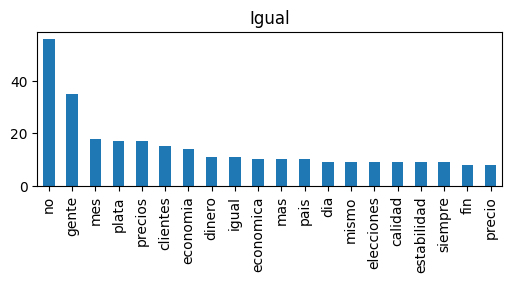

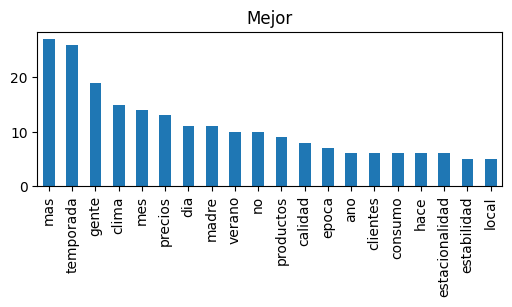

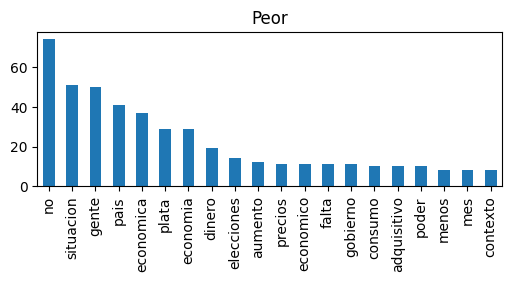

In [266]:
# visualizamos las palabras más populares de cada clase:
labels = list(df_data.columns)
n = 20

for label in labels:
    df_plot = df_data[label].sort_values(ascending=False).head(n)
    df_plot.plot(kind="bar", title=label, figsize=(6, 2))
    plt.show()

## Stemming vs Lemmatization

Vemos algunos ejemplos cómo quedan con Stemming

In [227]:
columna = "Motivo variacion ventas"
stemmer = SnowballStemmer("spanish")

# Tomamos respuestas reales como ejemplo
# examples = df[columna].dropna().head(3).tolist()
examples = df[df['Motivo variacion ventas'].str.contains('situación')]['Motivo variacion ventas'].head(10).tolist()

for example in examples:
    tokens = [
        palabra
        for palabra in word_tokenize(
            example.lower(),
            language="spanish"
        )
        if palabra.isalpha()
    ]

    stemmed = [stemmer.stem(palabra) for palabra in tokens]

    print("Texto original:", example)
    print("Tokens:", tokens)
    print("Stemming:", stemmed)
    print()

Vemos algunos ejemplos cómo quedan con Lemmatization

In [228]:
nlp = spacy.load("es_core_news_sm")

for example in examples:
    doc = nlp(example.lower())

    tokens = [
        token.text
        for token in doc
        if not token.is_punct
    ]

    lemmatized = [
        token.lemma_
        for token in doc
        if not token.is_punct
    ]

    print("Texto original:", example)
    print("Tokens:", tokens)
    print("Lematización:", lemmatized)
    print()

Viendo que Lematizacion funciono bastante bien, lo aplicamos.

Lo dejamos en comentario porque al final no funciono

In [267]:
# nlp = spacy.load("es_core_news_sm", disable=["parser", "ner"])
# columna = "Motivo variacion ventas"

# df[columna + '- Lemmatizado'] = [
#     " ".join(token.lemma_.lower() for token in doc if not token.is_space)
#     for doc in nlp.pipe(
#         df[columna].fillna("").astype(str),
#         batch_size=64
#     )
# ]

## Exploracion III

Más exploración: regex para palabras directamente asociadas a la columna objetivo

In [231]:
patron = (
    r"\b(?:"
    r"aument\w*|increment\w*|sub\w*|"
    r"baj\w*|disminu\w*|"
    r"manten\w*|igual\w*|establ\w*"
    r")\b"
)

regex_words = (
    df["Motivo variacion ventas"]
    .str.findall(patron)
    .explode()
    .dropna()
)

regex_words.value_counts()

mask = df["Motivo variacion ventas"].str.contains(
    patron,
    regex=True,
    na=False
)

df.loc[mask, "Motivo variacion ventas"].head(20)

,Motivo variacion ventas
0,grande empresario aumentar costo
5,aumentar precio
6,calor hacer aumente venta bebido
7,cerca verano mantener plano
12,incremento precio aumentar costo
28,estable
32,estar bajar gente no platar comprar hacer 2 an...
39,bajo venta
43,ingreso mensual client bajo
44,bajo consumo economia nacional


In [232]:
regex_words.value_counts()


,count
Motivo variacion ventas,
bajo,27
aumento,22
aumentar,21
igual,16
mantener,13
disminuir,9
subir,5
bajar,4
incremento,3


Otro

In [272]:
patron_bigrama_no = r"(?<![a-záéíóúüñ])no\s+[a-záéíóúüñ]+"

df["bigramas_con_no"] = df[columna].str.findall(
    patron_bigrama_no,
    flags=re.IGNORECASE
)

casos_con_no = df[df["bigramas_con_no"].str.len() > 0]

print("Respuestas con bigramas que empiezan con 'no':", len(casos_con_no))
casos_con_no[[columna,"bigramas_con_no"]].head(20)


Respuestas con bigramas que empiezan con 'no': 126


,Motivo variacion ventas,bigramas_con_no
3,no contesta,[no contesta]
11,siempre mismos clientes no variacion,[no variacion]
26,no mas plata alcance,[no mas]
32,estan bajando gente no plata comprar hace 2 an...,[no plata]
36,gente no plata comprar,[no plata]
40,gente especula elecciones octubre no consume,[no consume]
50,no plata poca venta,[no plata]
51,consumidor no plata,[no plata]
54,aumentaron opciones menu comidas aceptamos tar...,[no lugares]
58,gente no plata,[no plata]


In [275]:
frecuencia_bigramas_no = (
    df["bigramas_con_no"]
    .explode()
    .dropna()
    .str.lower()
    .value_counts()
)

frecuencia_bigramas_no.index.unique()

Index(['no plata', 'no dinero', 'no llega', 'no sabe', 'no alcanza',
       'no consumo', 'no variacion', 'no movimiento', 'no compra',
       'no responde', 'no consume', 'no gasta', 'no poder', 'no conocen',
       'no principio', 'no lugares', 'no diferencia', 'no populista',
       'no bueno', 'no busca', 'no flujo', 'no entran', 'no sufren',
       'no afecta', 'no aumentan', 'no mas', 'no contesta', 'no quiso',
       'no hace', 'no aumentos', 'no aumento', 'no suben', 'no subida',
       'no tan', 'no crecimiento', 'no comen', 'no aplica', 'no da',
       'no consenso', 'no encargos', 'no achica', 'no compran', 'no necesario',
       'no cambiaron', 'no gastar', 'no disponibilidad', 'no aumenta',
       'no cambia', 'no buenos', 'no dispone', 'no mismo', 'no primera',
       'no sucedio', 'no ningun', 'no piensa', 'no efectivo', 'no podes',
       'no personas', 'no influyo'],
      dtype='object', name='bigramas_con_no')

In [281]:
df[df['Motivo variacion ventas'].isin(['no sabe', 'no responde', 'no contesta', 'no quiso', 'no aplica'])]['Motivo variacion ventas'] = 'NC'

/tmp/ipykernel_630/3465946861.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[df['Motivo variacion ventas'].isin(['no sabe', 'no responde', 'no contesta', 'no quiso', 'no aplica'])]['Motivo variacion ventas'] = 'NC'


### Bigramas x clase

In [282]:
# Funcion de bigramas
# Display the most frequent words after cleaning. Unigrams or bigrams
def analizar_frecuencia_palabras(series_texto, titulo, n_palabras, bigramas=False):
    if bigramas:
      vectorizer = CountVectorizer(ngram_range=(2, 2))
    else:
      vectorizer = CountVectorizer(ngram_range=(1, 1))
    X = vectorizer.fit_transform(series_texto.astype(str))
    frecuencias = dict(zip(vectorizer.get_feature_names_out(), X.sum(axis=0).tolist()[0]))
    top_n = Counter(frecuencias).most_common(n_palabras)
    print(f"\n--- {titulo} ---")
    print("Las n palabras más frecuentes son:")
    for palabra, frecuencia in top_n:
        print(f"  - '{palabra}': {frecuencia}")
    return top_n

# Bigramas por expectativas - Cambian mucho entre los que crecieron vs no crecieron
ventas_disminuyeron = df.loc[df['Ventas'] == 'Peor', 'Motivo variacion ventas']
ventas_iguales = df.loc[df['Ventas'] == 'Igual', 'Motivo variacion ventas']
ventas_aumentaron = df.loc[df['Ventas'] == 'Mejor', 'Motivo variacion ventas']

bigramas_ventas_disminuyeron = analizar_frecuencia_palabras(ventas_disminuyeron, f'ventas_disminuyeron', 10, bigramas=True)
bigramas_ventas_iguales = analizar_frecuencia_palabras(ventas_iguales, f'ventas_iguales', 10, bigramas=True)
bigramas_ventas_aumentaron = analizar_frecuencia_palabras(ventas_aumentaron, f'ventas_aumentaron', 10, bigramas=True)


--- ventas_disminuyeron ---
Las n palabras más frecuentes son:
  - 'gente no': 29
  - 'situacion economica': 27
  - 'no plata': 22
  - 'situacion pais': 18
  - 'economica pais': 11
  - 'no dinero': 11
  - 'poder adquisitivo': 9
  - 'economia pais': 7
  - 'contexto economico': 6
  - 'no llega': 6

--- ventas_iguales ---
Las n palabras más frecuentes son:
  - 'gente no': 13
  - 'no plata': 13
  - 'fin mes': 7
  - 'situacion economica': 6
  - 'economica pais': 4
  - 'no dinero': 4
  - 'dia dia': 3
  - 'falta dinero': 3
  - 'mismos clientes': 3
  - 'no consumo': 3

--- ventas_aumentaron ---
Las n palabras más frecuentes son:
  - 'dia madre': 10
  - 'temporada verano': 5
  - 'calidad productos': 3
  - 'cambio temporada': 3
  - 'epoca ano': 3
  - 'hace mas': 3
  - 'mas gente': 3
  - 'mes pasado': 3
  - 'redes sociales': 3
  - 'temporada alta': 3


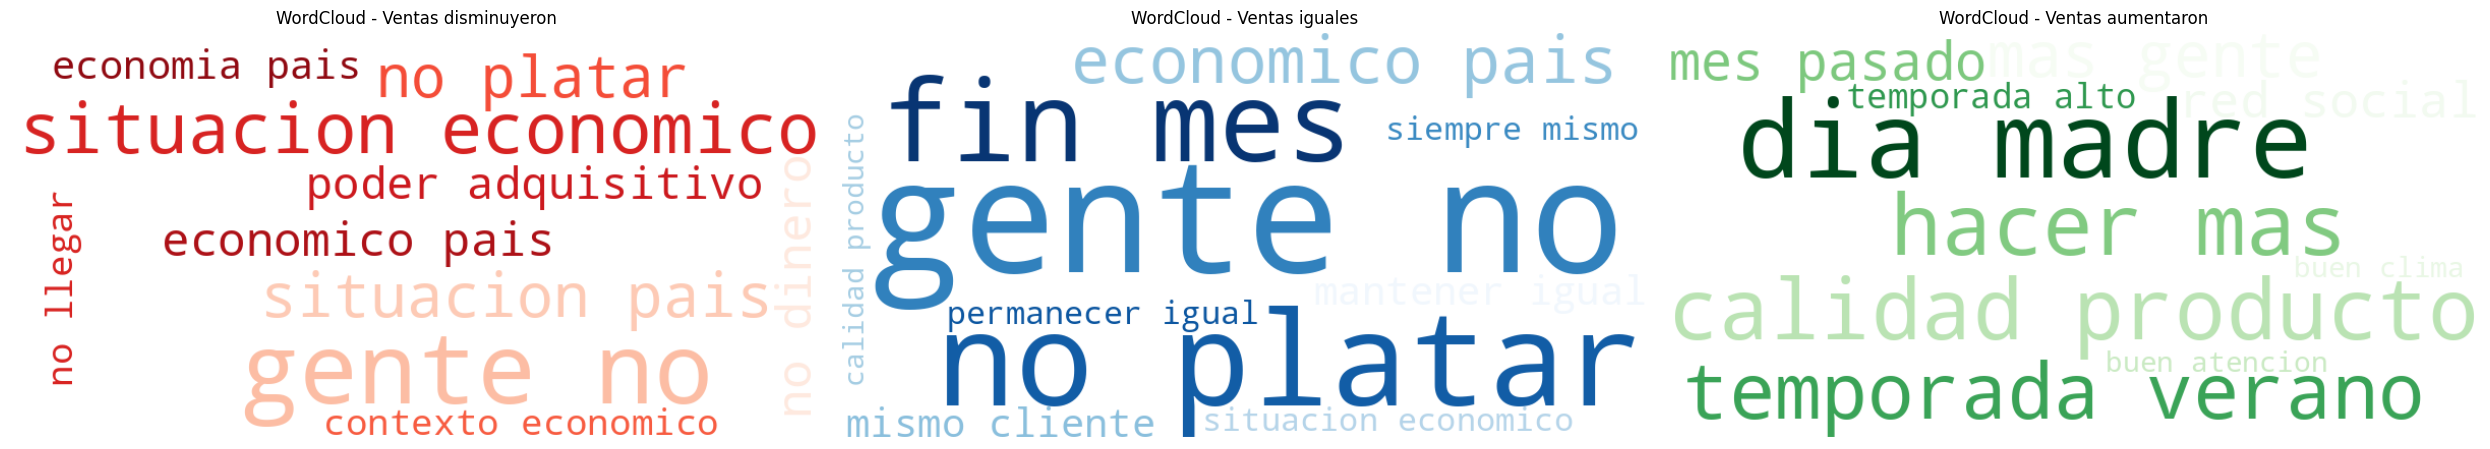

In [234]:
# @title
def generate_wordcloud(bigrams_data, title, ax, colormap='viridis'):
    # Convert list of (bigram, frequency) tuples to a dictionary
    word_freq_dict = {bigram: freq for bigram, freq in bigrams_data}

    # Generate Word Cloud with specified colormap
    wordcloud = WordCloud(width=800, height=400, background_color='white', colormap=colormap).generate_from_frequencies(word_freq_dict)

    # Display the generated image on the provided axes:
    ax.imshow(wordcloud, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(title)

# Create a figure with 1 row and 3 columns for side-by-side plots
fig, axes = plt.subplots(1, 3, figsize=(25, 10)) # Adjust figsize as needed

# Generate WordCloud for decreased sales (redder colormap)
generate_wordcloud(bigramas_ventas_disminuyeron, 'WordCloud - Ventas disminuyeron', axes[0], colormap='Reds')

# Generate WordCloud for equal sales (neutral colormap)
generate_wordcloud(bigramas_ventas_iguales, 'WordCloud - Ventas iguales', axes[1], colormap='Blues') # Using Blues for neutral

# Generate WordCloud for increased sales (greener colormap)
generate_wordcloud(bigramas_ventas_aumentaron, 'WordCloud - Ventas aumentaron', axes[2], colormap='Greens')

plt.tight_layout() # Adjust layout to prevent overlapping titles/labels
plt.show()